In [2]:
#################################################################################################################################################
# Project-2: Use Python to write a topology optimization code. Boundary conditions and meshes are given, check the 
# TO_inp folder: Mesh: 60x40 domain, 657 nodes, 616 elements. Fixed: left boundary nodes, Force: node 369 (mid-right), F=1 downward (y-direction)

#####################
# 1. Import Libraries
#####################
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

from IPython import display 
import time

import pandas as pd

In [3]:
#################
# 2. Import Data
#################
# import the node, element, fixed node, force node

node_list    = np.delete(pd.DataFrame.to_numpy(
                   pd.read_csv('node.txt',    sep=',', header=None)), [0], axis=1)

element_list = np.delete(pd.DataFrame.to_numpy(
                   pd.read_csv('element.txt', sep=',', header=None)), [0], axis=1)

force_node   = pd.DataFrame.to_numpy(
                   pd.read_csv('force.txt',   sep=',', header=None))

fixed_node   = pd.DataFrame.to_numpy(
                   pd.read_csv('fixed.txt',   sep=',', header=None))
# Verify
print("node_list shape:   ", node_list.shape)      # (697, 2)
print("element_list shape:", element_list.shape)   # (640, 4)
print("force_node:        ", force_node)           # [[369]]
print("fixed_node:        ", fixed_node)           # [[1,42,83,...,657]]

node_list shape:    (697, 2)
element_list shape: (640, 4)
force_node:         [[369]]
fixed_node:         [[  1  42  83 124 165 206 247 288 329 370 411 452 493 534 575 616 657]]


In [4]:
##############################################
#3.  calculate the area and center of elements
##############################################
def cal_area(point_1,point_2,point_3,point_4):
    area = np.abs((point_1[0]*point_2[1]-point_2[0]*point_1[1]) + (point_2[0]*point_3[1]-point_3[0]*point_2[1]) + 
    (point_3[0]*point_4[1]-point_4[0]*point_3[1]) + (point_4[0]*point_1[1]-point_1[0]*point_4[1]))/2
    return area

In [5]:
def area_center(node_list, element_list):
    center = np.zeros((element_list.shape[0],2))
    area = np.zeros(element_list.shape[0])
    for i in range(element_list.shape[0]):
        xy_coordinate = node_list[element_list[i,:]-1,:]
        center[i,0] = np.average(xy_coordinate[:,0])
        center[i,1] = np.average(xy_coordinate[:,1])
        area[i] = cal_area(xy_coordinate[0,:],xy_coordinate[1,:],xy_coordinate[2,:],xy_coordinate[3,:])
    return area, center

In [6]:
##############
# 4. FEA Code
##############
# (a). write the B matrix
def B_matrix(xi,eta):
    B1 = 1/4 * np.array([[-1+eta, 0],[0,-1+xi],[-1+xi,-1+eta]])
    B2 = 1/4 * np.array([[1-eta, 0],[0,-1-xi],[-1-xi,1-eta]])
    B3 = 1/4 * np.array([[1+eta, 0],[0,1+xi],[1+xi,1+eta]])
    B4 = 1/4 * np.array([[-1-eta, 0],[0,1-xi],[1-xi,-1-eta]])
    B = np.concatenate((B1,B2,B3,B4),axis = 1)
    return B

In [7]:
#-------------------------
# (b). write the D matrix
#-------------------------

def D_matrix(E,v):
    D = E/(1-v**2) * np.array([[1,v,0],[v,1,0],[0,0,(1-v)/2]])
    return D

In [8]:
#---------------------------------------------
# (c). calculate the element-stiffness matrix
#---------------------------------------------
def stiffness_matrix(E,v, gauss_points):
    D = D_matrix(E,v)
    k_element = np.zeros((8,8))
    for i in range(gauss_points.shape[0]):
        B = B_matrix(gauss_points[i,0],gauss_points[i,1])

        k_element = k_element + np.matmul(B.T, np.matmul(D, B))
    return k_element

In [9]:
#--------------------------------------------------
# (d). define the finite element analysis function
#--------------------------------------------------
def global_stiffness_matrix(node_list, element_list, x, penal, E, v, gauss_points):
    # initialize the global matrix k
    k_global = np.zeros((node_list.shape[0]*2,node_list.shape[0]*2))
    k_local = stiffness_matrix(E, v, gauss_points)
    # assemble the global matrix
    for i in range(element_list.shape[0]):
        xy_coordinate = node_list[element_list[i,:]-1,:]

        global_index = np.array([element_list[i,:]*2-2,element_list[i,:]*2-1]).flatten('F')

        E_dof = global_index.shape[0]

        for j in range(E_dof):
            for k in range(E_dof):
                k_global[global_index[j], global_index[k]] += x[i]**penal * k_local[j, k]
        
    return k_global

In [15]:
#--------------------------------------
# (e). Apply BCs and reduce the system
#--------------------------------------
def solve_FE(k_global, force_node, fixed_node):
        
    # Initiate f
    f = np.zeros((node_list.shape[0]*2,1))
    u = np.zeros((node_list.shape[0]*2,1))
    f[force_node*2-1,0] = 1
    fixed_dof   = np.concatenate((fixed_node*2-2, [[21*2-1]]), axis=1)

    k_reduced = np.delete(k_global, fixed_dof, axis = 0)
    k_reduced = np.delete(k_reduced, fixed_dof, axis = 1)
    f_reduced = np.delete(f, fixed_dof, axis = 0)
    free_dof = np.delete(np.arange(node_list.shape[0]*2),fixed_dof)
    u[free_dof] = np.linalg.solve(k_reduced,f_reduced)

    return u

In [16]:
##########################
# 5. Topology Optimization
##########################
# a)- Apply Classic Sigmund density-based Method
#------------------------------------------------
def mesh_independency(center, rmin, x, dc):
    # Sensitivity filter — weighted average within radius rmin to prevent checkerboard patterns & mesh dependency.
    # where, rmin: sensitifity filter raduis, x: density element (rho), and dc: sensitifity of compliance with respect to x 
   
    n_elem = len(x)
    dcn    = np.zeros(n_elem)
    for i in range(n_elem): 
        total_weight = 0.0
        for j in range(n_elem):
            dist = np.sqrt((center[i, 0] - center[j, 0])**2 +
                           (center[i, 1] - center[j, 1])**2)
            fac = rmin - dist
            if fac > 0:
                total_weight += fac
                dcn[i]       += fac * x[j] * dc[j]
        dcn[i] /= (x[i] * total_weight + 1e-10)
    return dcn

In [17]:
#--------------------------------------
# b)- Apply Optimality Criteria Method
#--------------------------------------
def optimality_criteria(area, x, volfrac, dc):
    # Bisection on Lagrange multiplier to enforce volume constraint
    # where, x: density element (rho), volfrac: target volume fraction, and dc: sensitifity of compliance with respect to x 

    total_area = np.sum(area)
    target_vol = volfrac * total_area

    l1, l2  = 0.0, 1e9
    move    = 0.2
    x_new   = x.copy()

    while (l2 - l1) / (l2 + l1 + 1e-40) > 1e-4:
        lmid  = 0.5 * (l1 + l2)
        # OC update rule
        x_new = np.maximum(1e-3,
                np.maximum(x - move,
                np.minimum(1.0,
                np.minimum(x + move,
                           x * np.sqrt(np.maximum(-dc, 1e-10) / lmid)))))
        # Check volume
        if np.dot(area, x_new) > target_vol:
            l1 = lmid
        else:
            l2 = lmid

    return x_new

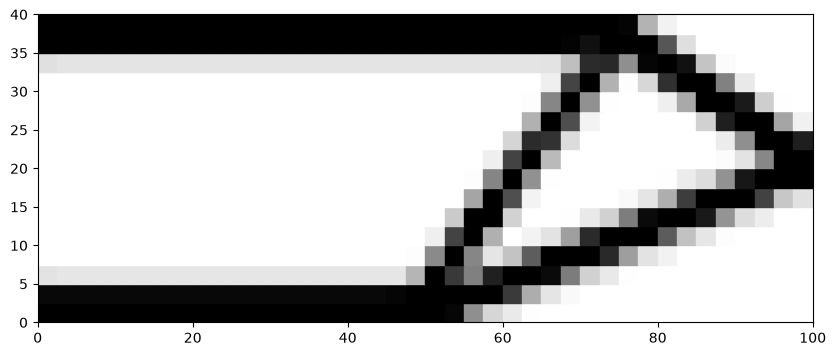

None

1001 interation run


In [21]:
#############################
# c)-The main TO driver Setup
#############################
area, center = area_center(node_list, element_list)

# write the Gauss Quadrature Integration points
gauss_points = np.array([[-1/np.sqrt(3),-1/np.sqrt(3)],
                [1/np.sqrt(3),-1/np.sqrt(3)],
                [1/np.sqrt(3),1/np.sqrt(3)],
                [-1/np.sqrt(3),1/np.sqrt(3)]])

E = 1
v = 0.25

penal = 5
rmin = 3
volfrac = 0.3

x = np.ones(element_list.shape[0])*volfrac  # x is the density of each element, the initial value is 0.3 for all

loop = 0
loop_max = 1000    # if the while loop doesn't converges in loop_max iteration, it stops
change = 1       # initialize the stop criteria
dc = np.zeros(element_list.shape[0])   # initialize the dc

# start TO iteration
while change > 0.001:
    loop = loop + 1
    x_old = x.copy()            # copy x to calculate change later
    
    # FE analysis
    k_global = global_stiffness_matrix(node_list, element_list, x, penal, E, v, gauss_points)
    
    u = solve_FE(k_global, force_node, fixed_node)
    
    
    # objective function and sensitivity analysis
    
    ke = stiffness_matrix(E, v, gauss_points)
    
    c = 0   # initialize the value of objective function
    
    for i in range(element_list.shape[0]):
        # find the displacement on each element
        global_index = np.array([element_list[i,:]*2-2,element_list[i,:]*2-1]).flatten('F')
        ue = u[global_index,:]
        
        ###########################################################
        # (1) accumulate the objective function c
        val  = float((ue.T @ ke @ ue).flatten()[0])
        c   += x[i]**penal * val

        # (2) calculate the gradient dc[i]
        dc[i] = -penal * x[i]**(penal-1) * val
        ###########################################################
        
    # Call the  AW mesh_independency function to update dc
    dc = mesh_independency(center, rmin, x, dc)
    
    # Call the optimality_criteria function to update dc
    x = optimality_criteria(area, x, volfrac, dc)

    # calculate how much the design variable changed
    change = np.max(np.max(np.abs(x-x_old))) 
    #plot
    
    fig, ax = plt.subplots(figsize=(10, 4))
    
    ax.autoscale(enable=True) 

    for i in range(element_list.shape[0]):
        xy_coordinate = node_list[element_list[i,:]-1,:]

        p = Polygon(xy_coordinate,color = [1-x[i],1-x[i],1-x[i]])
        ax.add_patch(p)


    plt.xlim([0, 100])
    plt.ylim([0, 40])
    
    display.clear_output(wait=True)
    display.display(plt.show()) 
    time.sleep(0.01) 
    if loop>loop_max:
        break
print(loop, "interation run") 